# Homework 8

**Due: 11/13/2020 on gradescope**

## References

+ Lectures 21-23 (inclusive).


## Instructions

+ Type your name and email in the "Student details" section below.
+ Develop the code and generate the figures you need to solve the problems using this notebook.
+ For the answers that require a mathematical proof or derivation you can either:
    
    - Type the answer using the built-in latex capabilities. In this case, simply export the notebook as a pdf and upload it on gradescope; or
    - You can print the notebook (after you are done with all the code), write your answers by hand, scan, turn your response to a single pdf, and upload on gradescope.

+ The total homework points are 100. Please note that the problems are not weighed equally.

**Note**: Please match all the pages corresponding to each of the questions when you submit on gradescope.

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_context('paper')
sns.set_style('white')
import scipy.stats as st
# A helper function for downloading files
import requests
import os
def download(url, local_filename=None):
    """
    Downloads the file in the ``url`` and saves it in the current working directory.
    """
    if local_filename is None:
        local_filename = os.path.basename(url)
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
    except requests.RequestException as exc:
        # Fall back to an existing copy if the server is unreachable.
        if os.path.exists(local_filename):
            print(f"Download failed ({type(exc).__name__}); using local {local_filename}.")
            return
        raise
    with open(local_filename, 'wb') as fd:
        fd.write(response.content)
try:
  import GPy
except ImportError as exc:
  raise ImportError("Install GPy before running this legacy homework notebook.") from exc
import scipy.stats as st

np.random.seed(53908)

## Problem 1 - Defining priors on function spaces

In this problem we are going to explore further how Gaussian processes can be used to define probability measures over function spaces.
To this end, assume that there is a 1D function, call if $f(x)$, which we do not know.
For simplicity, assume that $x$ takes values in $[0,1]$.
We will employ Gaussian process regression to encode our state of knowledge about $f(x)$ and sample some possibilities for it.
For each of the cases below:
+ assume that $f\sim \operatorname{GP}(m, k)$ and pick a mean ($m(x)$) and a covariance function $f(x)$ that match the provided information.
+ write code that samples a few times (up to five) the values of $f(x)$ at a 100 equidistant points between 0 and 1.

### Part A - Super smooth function with known length scale

Assume that you hold the following beliefs
+ You know that $f(x)$ has as many derivatives as you want and they are all continuous
+ You don't know if $f(x)$ has a specific trend.
+ You think that $f(x)$ has "wiggles" that are approximatly of size $\Delta x=0.1$.
+ You think that $f(x)$ is between -4 and 4.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:**

**I am doing this for you so that you have a concrete example of what is requested.**

The mean function should be:
$$
m(x) = 0.
$$
The covariance function should be a squared exponential:
$$
k(x,x') = s^2\exp\left\{-\frac{(x-x')^2}{2\ell^2}\right\},
$$
with variance:
$$
s^2 = k(x,x) = \mathbb{V}[f(x)] = 4,
$$
and lengthscale $\ell = 0.1$.
We chose the variance to be 4 so that with (about) 95% probability the values of $f(x)$ are between -4 and 4.

</div>

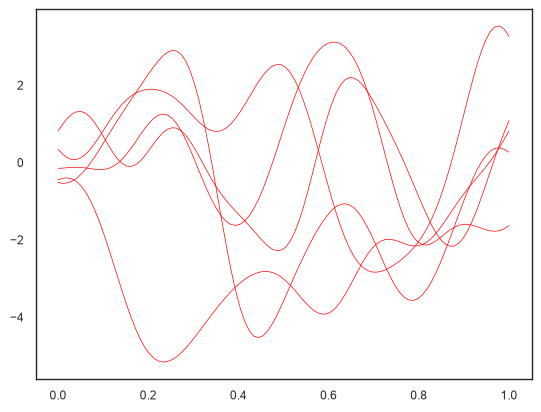

In [2]:
# Define the covariance function
k = GPy.kern.RBF(1)
k.lengthscale = 0.1
k.variance = 4.0
# Sample
xs = np.linspace(0, 1, 100)
# The mean function at xs
ms = np.zeros(xs.shape)
# Find the covariance matrix. You need to add a small number
# to the diagonal to ensure numerical stability
nugget = 1e-6
K = k.K(xs[:, None]) + nugget * np.eye(xs.shape[0])
# A multivariate normal that can be used to sample the function values
F = st.multivariate_normal(mean=ms.flatten(), cov=K)
# Take the function samples
f_samples = F.rvs(size=5)
# Plot the samples
fig, ax = plt.subplots(dpi=100)
ax.plot(xs, f_samples.T, 'r', lw=0.5);

### Part B - Super smooth function with known ultra small length scale

Assume that you hold the following beliefs
+ You know that $f(x)$ has as many derivatives as you want and they are all continuous
+ You don't know if $f(x)$ has a specific trend.
+ You think that $f(x)$ has "wiggles" that are approximatly of size $\Delta x=0.05$.
+ You think that $f(x)$ is between -3 and 3.


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I use a zero mean because no trend is preferred, and a squared-exponential covariance because its sample functions are infinitely differentiable. Following the Part A example, I want $\pm3$ to be about two standard deviations, so I use $s=1.5$ and variance $s^2=2.25$. This puts about 95% of the pointwise values within $\pm2.94\approx\pm3$. The lengthscale is $0.05$, matching the requested wiggle scale. The code below samples five functions at 100 evenly spaced inputs.

</div>

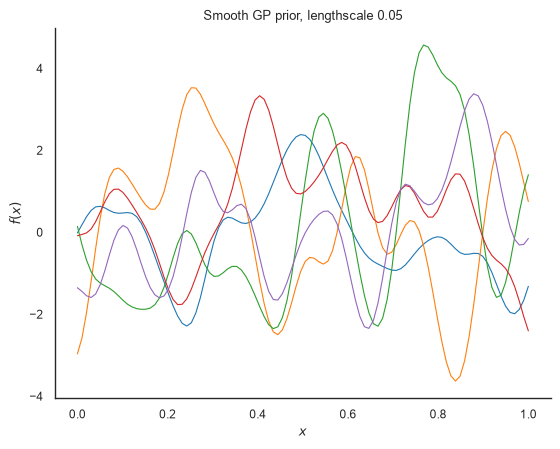

In [3]:
# A zero mean expresses no preferred trend. The squared-exponential kernel
# gives infinitely differentiable paths; variance 2.25 gives an approximate
# pointwise 95% range of +/-3, and lengthscale 0.05 gives fine-scale wiggles.
k = GPy.kern.RBF(input_dim=1, variance=2.25, lengthscale=0.05)
xs = np.linspace(0.0, 1.0, 100)


def plot_gp_prior(kernel, title):
    covariance = kernel.K(xs[:, None]) + 1e-6 * np.eye(xs.size)
    prior = st.multivariate_normal(mean=np.zeros(xs.size), cov=covariance)
    samples = prior.rvs(size=5)
    fig, ax = plt.subplots(dpi=100)
    ax.plot(xs, samples.T, lw=0.8)
    ax.set(xlabel="$x$", ylabel="$f(x)$", title=title)
    sns.despine(ax=ax)
    plt.show()


plot_gp_prior(k, "Smooth GP prior, lengthscale 0.05")

### Part C - Continuous function with known length scale

Assume that you hold the following beliefs
+ You know that $f(x)$ is continuous, nowhere differentiable.
+ You don't know if $f(x)$ has a specific trend.
+ You think that $f(x)$ has "wiggles" that are approximatly of size $\Delta x=0.1$.
+ You think that $f(x)$ is between -5 and 5.

Hint: Use ``GPy.kern.Exponential``.


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I use zero mean, since no trend is specified, and the exponential covariance with variance $6.25$ and lengthscale $0.1$. The exponential kernel has continuous sample paths that are almost surely nowhere differentiable. Its pointwise standard deviation is $2.5$, so about 95% of marginal values fall within roughly $\pm4.9$; this makes the requested $[-5,5]$ range a reasonable pointwise scale, not a strict bound.

</div>

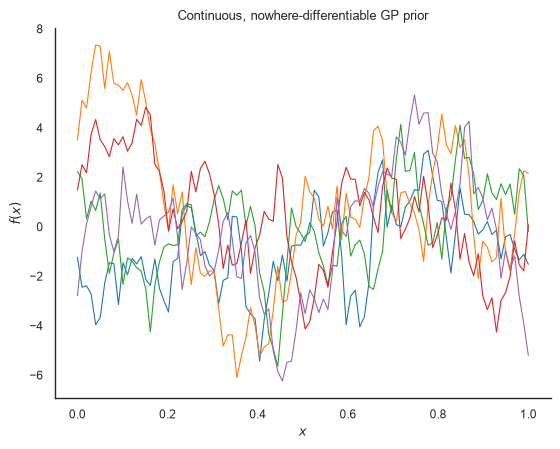

In [4]:
# The exponential kernel gives continuous, nowhere-differentiable paths.
k_continuous = GPy.kern.Exponential(input_dim=1, variance=6.25, lengthscale=0.1)
plot_gp_prior(k_continuous, "Continuous, nowhere-differentiable GP prior")

### Part D - Smooth periodic function with known length scale

Assume that you hold the following beliefs
+ You know that $f(x)$ is smooth.
+ You know that $f(x)$ is periodic with period 0.1.
+ You don't know if $f(x)$ has a specific trend.
+ You think that $f(x)$ has "wiggles" that are approximatly of size $\Delta x=0.5$ of the period.
+ You think that $f(x)$ is between -5 and 5.

Hint: Use ``GPy.kern.StdPeriodic``.


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I use a zero-mean standard periodic kernel with period $0.1$, variance $6.25$ (pointwise standard deviation $2.5$), and relative lengthscale $0.5$. In GPy's periodic kernel the lengthscale is a dimensionless fraction of the period; thus $0.5$ corresponds to a within-period scale of $0.05$. This encodes smooth repeating functions with a typical pointwise 95% range near $[-5,5]$.

</div>

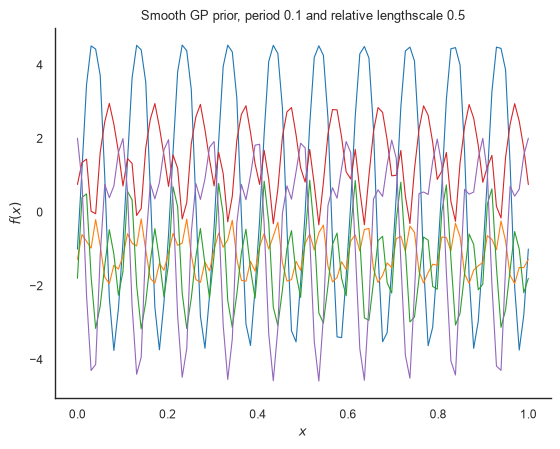

In [5]:
# GPy's periodic lengthscale is relative to the period: 0.5 gives broad,
# smooth within-period variation for a period of 0.1.
k_periodic_smooth = GPy.kern.StdPeriodic(
    input_dim=1, variance=6.25, lengthscale=0.5, period=0.1
)
plot_gp_prior(k_periodic_smooth, "Smooth GP prior, period 0.1 and relative lengthscale 0.5")

### Part E - Smooth periodic function with known length scale

Assume that you hold the following beliefs
+ You know that $f(x)$ is smooth.
+ You know that $f(x)$ is periodic with period 0.1.
+ You don't know if $f(x)$ has a specific trend.
+ You think that $f(x)$ has "wiggles" that are approximatly of size $\Delta x=0.1$ of the period (**the only thing that is different compared to D**).
+ You think that $f(x)$ is between -5 and 5.

Hint: Use ``GPy.kern.StdPeriodic``.


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I keep the same zero mean, variance, and period as in Part D, but reduce the relative lengthscale to $0.1$, corresponding to a within-period scale of $0.01$. The shorter lengthscale allows sharper within-period changes while the periodic kernel preserves repetition every $0.1$ units.

</div>

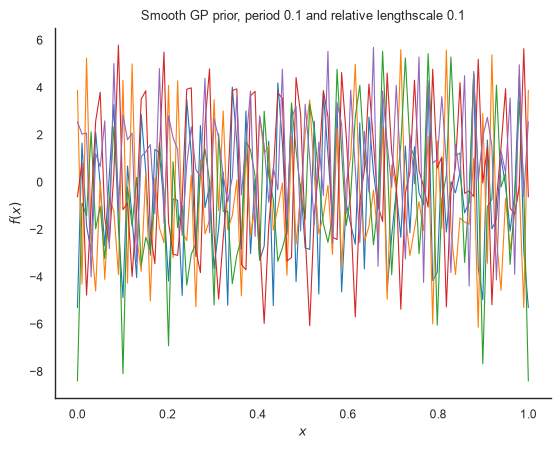

In [6]:
# Keep the period fixed and set the relative lengthscale to 0.1 of that period.
k_periodic_fine = GPy.kern.StdPeriodic(
    input_dim=1, variance=6.25, lengthscale=0.1, period=0.1
)
plot_gp_prior(k_periodic_fine, "Smooth GP prior, period 0.1 and relative lengthscale 0.1")

### Part F - The sum of two functions

Assume that you hold the following beliefs
+ You know that $f(x) = f_1(x) + f_2(x)$, where:
    - $f_1(x)$ is smooth with variance 2 and lengthscale 0.5
    - $f_2(x)$ is continuous, nowhere differentiable with variance 0.1 and lengthscale 0.1

Hint: You must create a new covariance function that is the sum of two other covariances.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** For independent zero-mean Gaussian processes, the sum is also a zero-mean Gaussian process, and its covariance is the sum of the component covariances. I use an RBF kernel for the smooth component and an exponential kernel for the continuous, rough component. Their variances and lengthscales are set to the stated values.

</div>

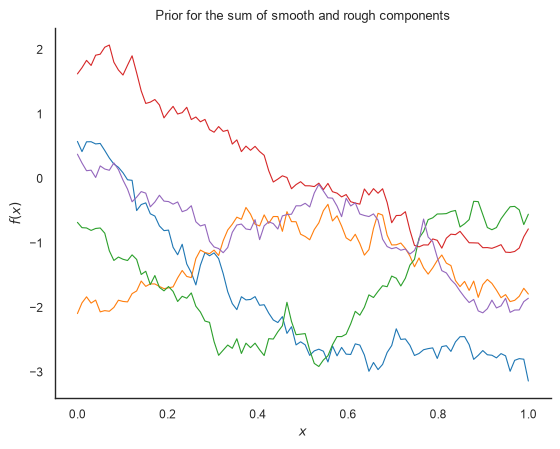

In [7]:
# Independent zero-mean components add their covariance functions.
k_f1 = GPy.kern.RBF(input_dim=1, variance=2.0, lengthscale=0.5)
k_f2 = GPy.kern.Exponential(input_dim=1, variance=0.1, lengthscale=0.1)
k_sum = k_f1 + k_f2
plot_gp_prior(k_sum, "Prior for the sum of smooth and rough components")

### Part G - The product of two functions

Assume that you hold the following beliefs
+ You know that $f(x) = f_1(x)f_2(x)$, where:
    - $f_1(x)$ is smooth, periodic (period = 0.1), lengthscale 0.1 (relative to the period), and variance 2.
    - $f_2(x)$ is smooth with lengthscale 0.5 and variance 1.

Hint: You must create a new covariance function that is the product of two other covariances.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I multiply a standard periodic covariance (period $0.1$, relative lengthscale $0.1$, variance $2$) by a squared-exponential covariance (lengthscale $0.5$, variance $1$). The product covariance has marginal variance $2$ and combines periodic behavior with a slowly varying smooth envelope. If $f_1$ and $f_2$ are independent zero-mean Gaussian processes, their pointwise product has this product covariance, although the product process itself is generally not Gaussian. The sampled curves below are GP draws with the requested product covariance.

</div>

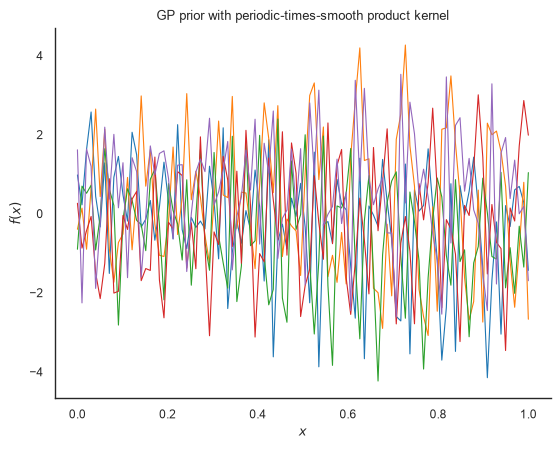

In [8]:
# Product kernel: relative periodic scale 0.1 (within-period scale 0.01),
# multiplied by the smooth envelope with lengthscale 0.5.
k_periodic_product = GPy.kern.StdPeriodic(
    input_dim=1, variance=2.0, lengthscale=0.1, period=0.1
)
k_smooth_product = GPy.kern.RBF(input_dim=1, variance=1.0, lengthscale=0.5)
k_product = k_periodic_product * k_smooth_product
plot_gp_prior(k_product, "GP prior with periodic-times-smooth product kernel")

## Problem 2

The National Oceanic and Atmospheric Administration (NOAA) has been measuring the levels of atmospheric CO2 at the Mauna Loa, Hawaii. The measurements start on March 1958 and go all the way to Janurary 2016.
The data can be found [here](http://www.esrl.noaa.gov/gmd/ccgg/trends/data.html).
The Python script below, downloads and plots the data set.

In [9]:
# The old course GitHub URL now returns 404; retrieve the same NOAA monthly
# mean file directly and retain only the assignment's original endpoint (Jan 2016).
url = 'https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.txt'
download(url, local_filename='mauna_loa_co2.txt')

In [10]:
# NOAA's current file has newer values; preserve the assignment's Jan 2016 cutoff.
data = np.loadtxt('mauna_loa_co2.txt')
data = data[(data[:, 0] < 2016) | ((data[:, 0] == 2016) & (data[:, 1] <= 1))]
# Keep valid monthly mean CO2 measurements (column 4; negative values denote missing data).
data = data[data[:, 3] > 0]
assert data.shape[1] >= 5
assert data[:, 2].max() <= 2016.05
print(f"Loaded {len(data)} monthly records through decimal year {data[-1, 2]:.4f}.")

Loaded 695 monthly records through decimal year 2016.0417.


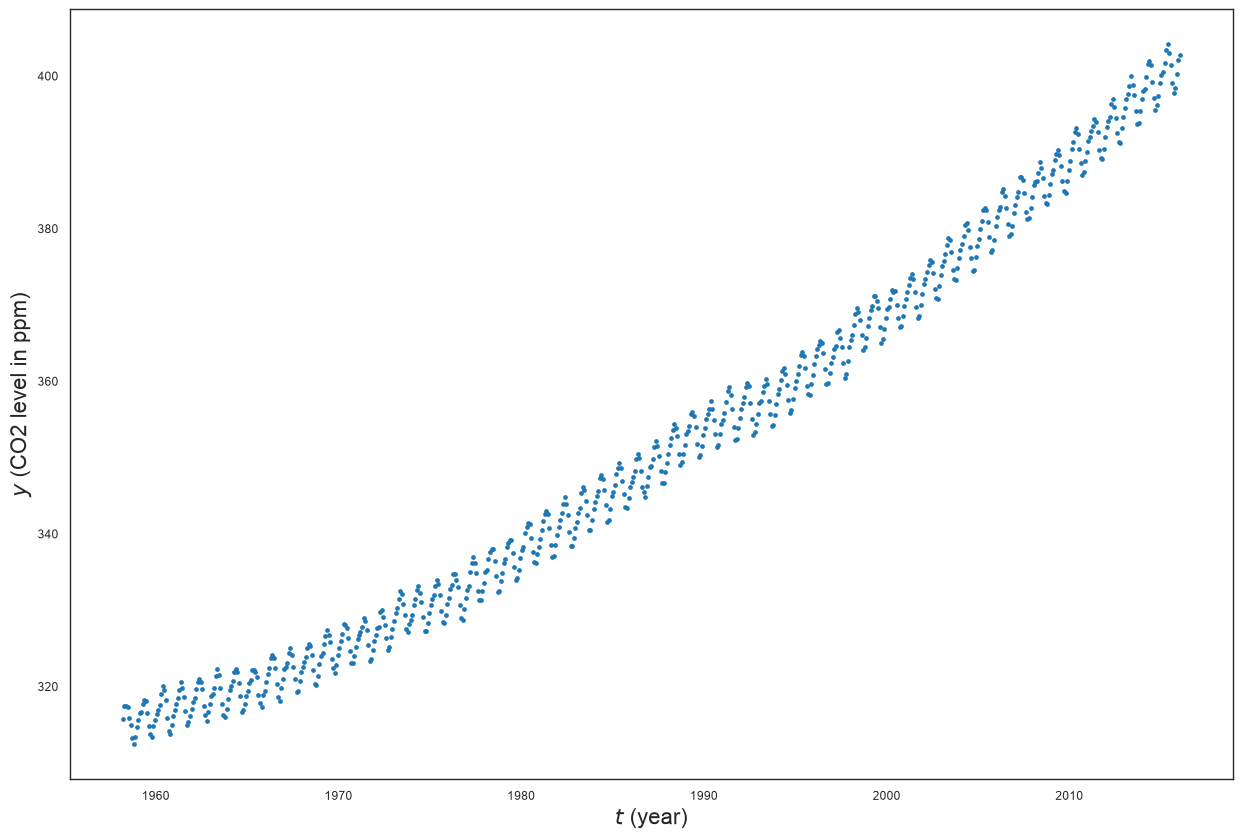

In [11]:
#load data 
t = data[:, 2][:, None]  #time (in decimal dates)
y = data[:, 3][:, None]  #monthly mean CO2 level (column 3; column 4 is NOAA's de-seasonalized series), in ppm
fig, ax = plt.subplots(1, figsize = (15, 10), dpi=100)
ax.plot(t, y, '.')
ax.set_xlabel('$t$ (year)', fontsize = 16)
ax.set_ylabel('$y$ (CO2 level in ppm)', fontsize = 16);

Overall, we observe a steady growth of CO2 levels. The wiggles correspond to seasonal changes. Since the vast majority of the population inhabits the Northen hemisphere, fuel consumption goes up during the Northen winters and CO2 emissions follow. Our goal is to study this dataset with Gaussian process regression. Specifically we would like to predict the evolution of the CO2 levels from Feb 2018 to Feb 2028 and quantify our uncertainty about this prediction.

It's always a good idea to work with at scaled version of the inptus and the outputs. We are going to scale the times as follows:
$$
t_s = t - t_{\min}.
$$
So, time is still in fractional years, but we start counting at zero instead of 1950.
We scale the $y$'s as:
$$
y_s = \frac{y - y_{\min}}{y_{\max}-y_{\min}}.
$$
This takes all the $y$ between $0$ and $1$.
Here is how the scaled data look like:

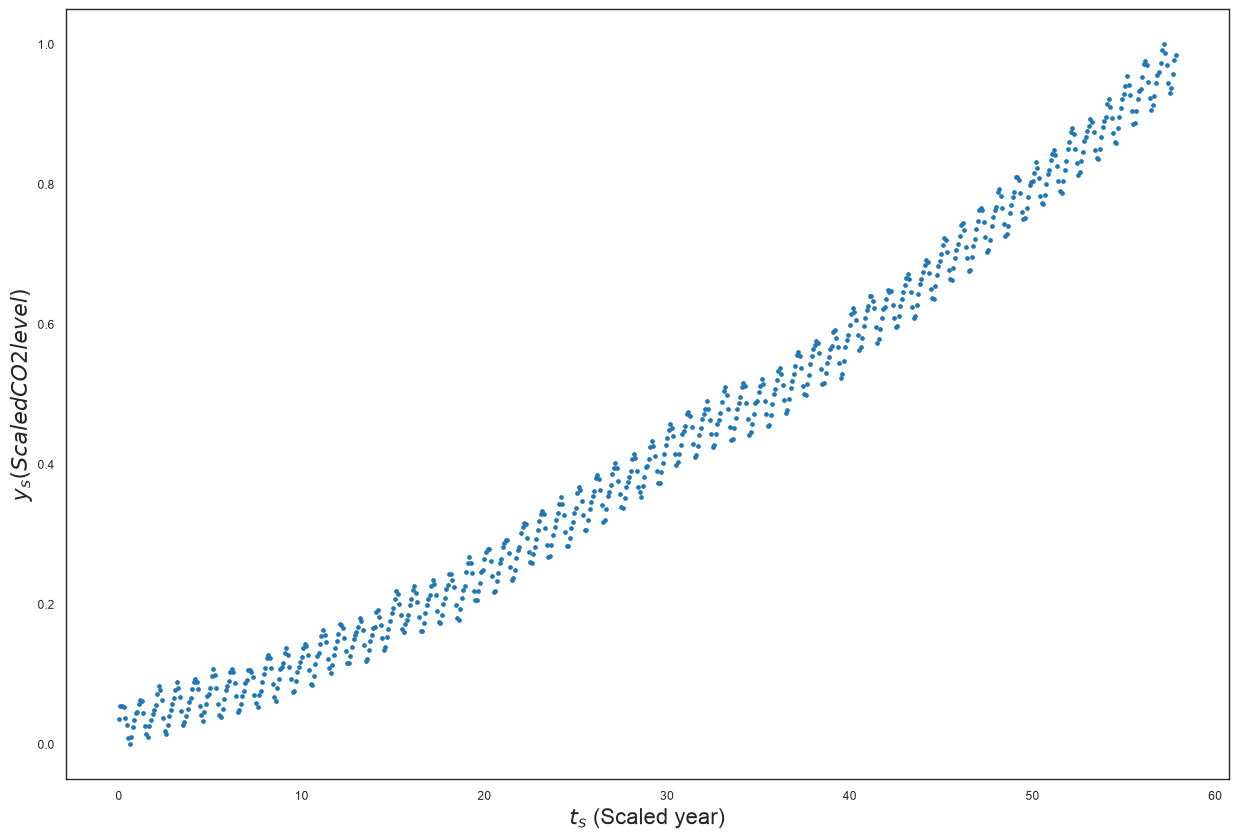

In [12]:
t_s = t - t.min()
y_s = (y - y.min()) / (y.max() - y.min())
fig, ax = plt.subplots(1, figsize = (15, 10), dpi=100)
ax.plot(t_s, y_s, '.')
ax.set_xlabel('$t_s$ (Scaled year)', fontsize = 16)
ax.set_ylabel('$y_s (Scaled CO2 level)$', fontsize = 16);

In what follows, just work with the scaled data as you develop your model.
Scale back to the original units for your final predictions.

## Part A - Naive approach

Use a zero mean Gaussian process with a squared exponential covariance function to fit the data and make the required prediction (ten years after the last observation).

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** The zero-mean RBF model follows the long-term rise over the observed period, but it cannot represent the annual cycle. The optimized noise variance absorbs the seasonal wiggles, so the 95% band is wide enough to cover them instead of tracking them. After the last observation, the predicted mean levels off (scaled value about $1.1$ at the end of the plot) because a stationary zero-mean RBF prior slowly reverts toward its zero mean away from the data. So this model is not credible for the seasonal pattern or for long-range growth.

</div>

In [13]:
# A zero-mean RBF prior is intentionally naive here: it has no long-run trend.
naive_kernel = GPy.kern.RBF(input_dim=1, variance=1.0, lengthscale=10.0)
naive_model = GPy.models.GPRegression(t_s, y_s, kernel=naive_kernel, noise_var=0.01)
naive_model.optimize(messages=False, max_iters=2000)
print("Naive GP fitted. Log marginal likelihood:", float(naive_model.log_likelihood()))

Naive GP fitted. Log marginal likelihood: 1600.606326297261


Predict everything:

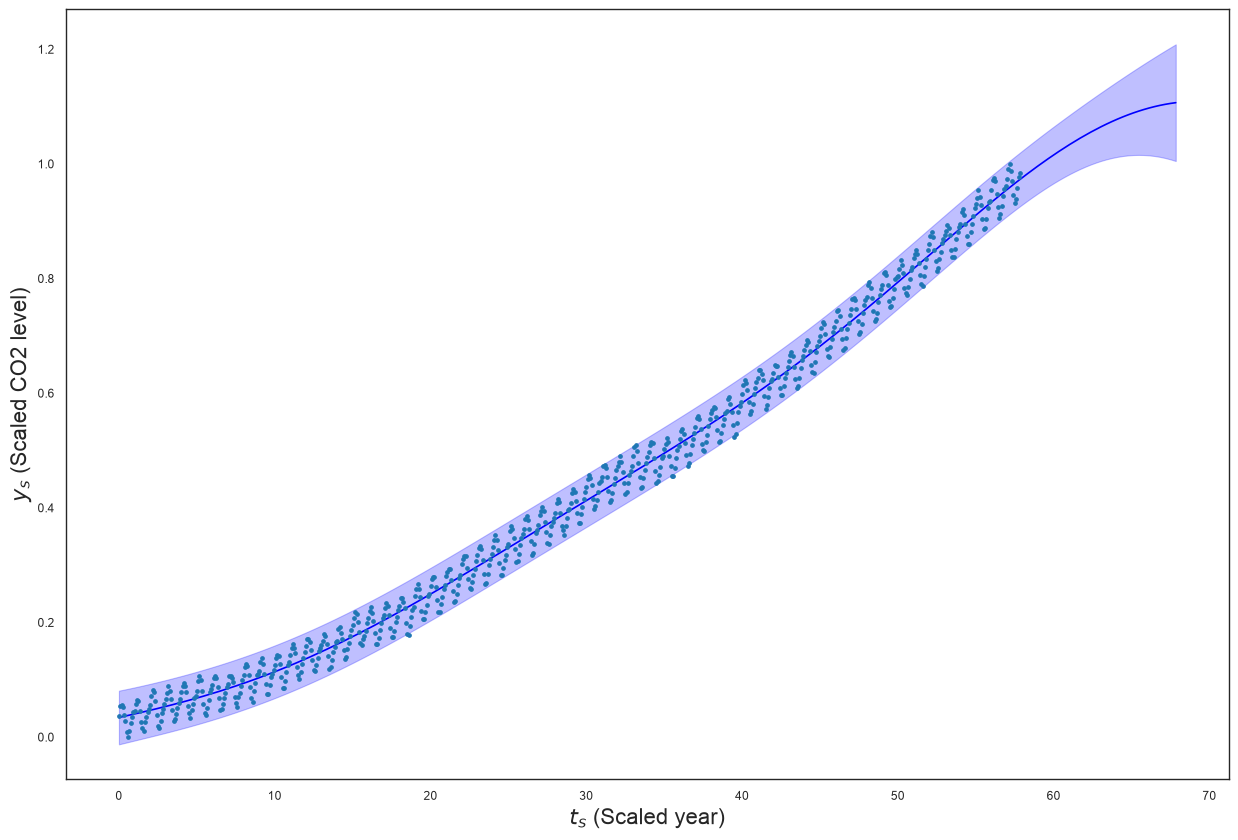

In [14]:
tss = np.linspace(0, t_s.max() + 10, 200)[:, None]
ys, vs = naive_model.predict(tss)
ls = ys - 1.96 * np.sqrt(vs)
us = ys + 1.96 * np.sqrt(vs)
fig, ax = plt.subplots(1, figsize = (15, 10), dpi=100)
ax.plot(tss, ys, color='blue', label='Posterior mean')
ax.fill_between(tss.flatten(), ls.flatten(), us.flatten(), color='blue', alpha=0.25)
ax.plot(t_s, y_s, '.', label='Scaled observed data')
ax.set_xlabel('$t_s$ (Scaled year)', fontsize = 16)
ax.set_ylabel('$y_s$ (Scaled CO2 level)', fontsize = 16);

Notice that the squared exponential covariance caputes the long terms, but it fails to capture the seasonal fluctuations. As a matter of fact the seasonabl fluctions as treated as noise. This is clearly false. How can we fix it?

## Part B - Improving the prior covariance

Now use the ideas of Problem 1, to come up with a covariance function that exhibits the following characteristics clearly visible in the data (call $f(x)$ the scaled CO2 level).
+ $f(x)$ is smooth
+ $f(x)$ has a clear trend with a multi-year lengthscale (it is also an increasing trend, but we are not going to impose this)
+ $f(x)$ has seasonal fluctuations with a period of one year
+ $f(x)$ exhibits small fluctuations within its period.

Use summation and multiplication of simple covariance functions to create a covariance function that exhibits these trends. Sample a few times from it.

Hint: Do not attempt to fit the data in any way. Just try to find a covariance function that has the right features. We also do not care about getting the parameters 100% right at this point. The parameters will be optimized later.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** The covariance is a sum of a long-lengthscale squared-exponential term (variance $0.5$, lengthscale 15 years), an annual standard-periodic term (period 1 year), and a product of that periodic term with a short-lengthscale squared-exponential term (lengthscale 0.15 years). The broad term allows a multi-year trend, the periodic term represents seasonality, and the product term adds small-scale within-season variation. The mean remains zero as requested; these are prior samples, not a fitted curve.

</div>

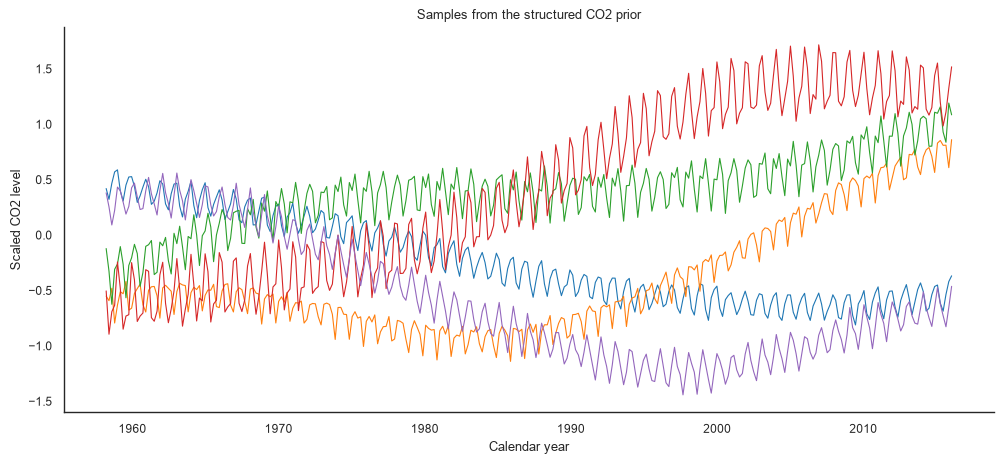

In [15]:
# Independent components encode a broad trend, annual seasonality, and
# short-scale within-season variation.
k_trend = GPy.kern.RBF(input_dim=1, variance=0.5, lengthscale=15.0)
k_season = GPy.kern.StdPeriodic(
    input_dim=1, variance=0.04, lengthscale=0.5, period=1.0
)
k_season.period.fix(1.0)
k_short = GPy.kern.RBF(input_dim=1, variance=0.01, lengthscale=0.15)
improved_kernel = k_trend + k_season + k_season * k_short

sample_x = np.linspace(0.0, t_s.max(), 300)
sample_covariance = improved_kernel.K(sample_x[:, None]) + 1e-6 * np.eye(sample_x.size)
sample_prior = st.multivariate_normal(
    mean=np.zeros(sample_x.size), cov=sample_covariance
)
prior_curves = sample_prior.rvs(size=5)
fig, ax = plt.subplots(figsize=(12, 5), dpi=100)
ax.plot(sample_x + t.min(), prior_curves.T, lw=0.8)
ax.set(xlabel="Calendar year", ylabel="Scaled CO2 level", title="Samples from the structured CO2 prior")
sns.despine(ax=ax)
plt.show()

## Part C - Predicting the future

Use a zero mean Gaussian process with the covariance function you picked above to do Gaussian process regression and make the required prediction (ten years after the last observation).

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I fit the zero-mean GP with the structured sum/product covariance from Part B, keeping the annual period fixed at one year, and transformed the forecast back to calendar years and ppm. The forecast repeats the annual cycle and keeps rising, and the 95% interval widens further from the data. For February 2028 the posterior mean is about $418.7$ ppm with a 95% interval of about $[408.5,\,428.8]$ ppm. The forecast grows only about $1$ ppm/year, which is slower than the roughly $2$ ppm/year rise at the end of the record. This happens because the long-term trend is still a stationary RBF term with a zero mean, so it slowly bends back toward the mean. A linear or quadratic mean function would probably capture the growth better.

</div>

Optimized log marginal likelihood: 2944.6363
February 2028 posterior mean: 418.68 ppm; 95% interval: [408.53, 428.83] ppm


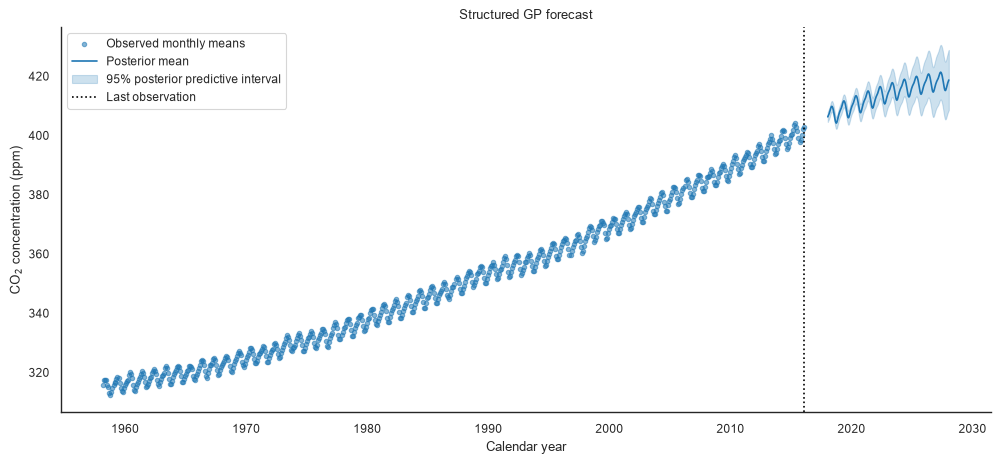

In [16]:
# Fix the seasonal period at one year and fit the structured prior to all data.
k_season.period.fix(1.0)
improved_model = GPy.models.GPRegression(
    t_s, y_s, kernel=improved_kernel.copy(), noise_var=0.001
)
improved_model.optimize(messages=False, max_iters=2000)

# Forecast from February 2018 through February 2028 in the original units.
forecast_calendar = np.linspace(t.min() + t_s.max() + 2.0, t.min() + t_s.max() + 12.0, 241)
forecast_scaled_time = (forecast_calendar - t.min())[:, None]
forecast_mean_scaled, forecast_variance_scaled = improved_model.predict(forecast_scaled_time)
output_range = float(y.max() - y.min())
forecast_mean_ppm = float(y.min()) + output_range * forecast_mean_scaled.ravel()
forecast_sd_ppm = output_range * np.sqrt(forecast_variance_scaled.ravel())

print(f"Optimized log marginal likelihood: {float(improved_model.log_likelihood()):.4f}")
print(
    f"February 2028 posterior mean: {forecast_mean_ppm[-1]:.2f} ppm; "
    f"95% interval: [{forecast_mean_ppm[-1] - 1.96 * forecast_sd_ppm[-1]:.2f}, "
    f"{forecast_mean_ppm[-1] + 1.96 * forecast_sd_ppm[-1]:.2f}] ppm"
)

fig, ax = plt.subplots(figsize=(12, 5), dpi=100)
ax.scatter(t.ravel(), y.ravel(), s=10, alpha=0.55, label="Observed monthly means")
ax.plot(forecast_calendar, forecast_mean_ppm, color="tab:blue", label="Posterior mean")
ax.fill_between(
    forecast_calendar,
    forecast_mean_ppm - 1.96 * forecast_sd_ppm,
    forecast_mean_ppm + 1.96 * forecast_sd_ppm,
    color="tab:blue", alpha=0.22, label="95% posterior predictive interval",
)
ax.axvline(t.max(), color="black", linestyle=":", label="Last observation")
ax.set(xlabel="Calendar year", ylabel="CO$_2$ concentration (ppm)", title="Structured GP forecast")
ax.legend()
sns.despine(ax=ax)
plt.show()

## Part D - Bayesian information criterion

As we have seen in earlier lectures, the Bayesian information criterion (BIC) can be used to compare two models. Fit both models with maximum likelihood and compute $\mathrm{BIC}=d\ln(n)-2\ln(\hat L)$; prefer the smaller value. The parameter count here includes the free kernel and likelihood-noise parameters.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** Using $n=695$ observations, the naive RBF model has $d=3$ free parameters, maximum log likelihood $1600.61$, and $\mathrm{BIC}\approx-3181.6$. The structured model has $d=9$ free parameters (the two fixed periods are not counted), maximum log likelihood $2944.64$, and $\mathrm{BIC}\approx-5830.4$. The structured model has the much smaller BIC, so it is preferred. Its gain in log likelihood is far larger than the penalty for its six extra parameters.

</div>

In [17]:
def model_bic(model, n_observations):
    '''Calculate BIC from the optimized log likelihood and free parameter count.'''
    # Count only free parameters; fixed ones (the one-year periods) are excluded.
    number_parameters = model.optimizer_array.size
    log_likelihood = float(model.log_likelihood())
    bic = number_parameters * np.log(n_observations) - 2.0 * log_likelihood
    return number_parameters, log_likelihood, bic


n_observations = len(t_s)
naive_parameters, naive_log_likelihood, naive_bic = model_bic(
    naive_model, n_observations
)
improved_parameters, improved_log_likelihood, improved_bic = model_bic(
    improved_model, n_observations
)
bic_comparison = pd.DataFrame(
    {
        "Free parameters": [naive_parameters, improved_parameters],
        "Max log likelihood": [naive_log_likelihood, improved_log_likelihood],
        "BIC": [naive_bic, improved_bic],
    },
    index=["Naive RBF", "Structured sum/product"],
)
print(bic_comparison.to_string(float_format=lambda value: f"{value:.4f}"))
print("Preferred by BIC:", bic_comparison["BIC"].idxmin())

                        Free parameters  Max log likelihood        BIC
Naive RBF                             3           1600.6063 -3181.5809
Structured sum/product                9           2944.6363 -5830.3775
Preferred by BIC: Structured sum/product


## Part E - Plot samples from the posterior Gaussian process

Using the model of Part C, plot 5 samples from the posterior Gaussian process between 2018 and 2028.

Hint: Use `GPy.models.GPRegression.posterior_samples_f`.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** The code plots five latent draws from the fitted posterior over the requested forecast interval and converts them back to ppm. They show plausible uncertainty in the future trajectory; unlike posterior-predictive draws, they do not add independent measurement noise.

</div>

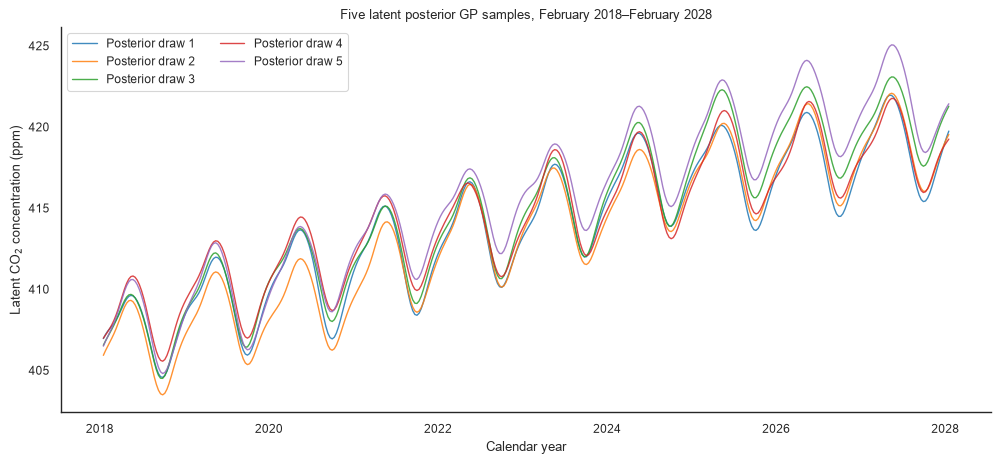

In [18]:
# Draw latent posterior functions, so these samples do not include observation noise.
posterior_sample_grid = np.linspace(forecast_calendar[0], forecast_calendar[-1], 400)
posterior_sample_times = (posterior_sample_grid - t.min())[:, None]
posterior_samples_scaled = improved_model.posterior_samples_f(
    posterior_sample_times, size=5
).reshape(posterior_sample_grid.size, 5)
posterior_samples_ppm = y.min() + output_range * posterior_samples_scaled

fig, ax = plt.subplots(figsize=(12, 5), dpi=100)
for index in range(posterior_samples_ppm.shape[1]):
    ax.plot(
        posterior_sample_grid,
        posterior_samples_ppm[:, index],
        linewidth=1.0,
        alpha=0.85,
        label=f"Posterior draw {index + 1}",
    )
ax.set(
    xlabel="Calendar year",
    ylabel="Latent CO$_2$ concentration (ppm)",
    title="Five latent posterior GP samples, February 2018–February 2028",
)
ax.legend(ncol=2)
sns.despine(ax=ax)
plt.show()

## Problem 3 - Using Bayesian Global optimization to calibrate an expensive physical model

This is Example 3.1 of [(Tsilifis, 2014)](http://arxiv.org/abs/1410.5522).

Consider the catalytic
conversion of nitrate ($\mbox{NO}_3^-$) to nitrogen ($\mbox{N}_2$) and other
by-products by electrochemical means.
The mechanism that is followed is complex and not well understood.
The experiment of [(Katsounaros, 2012)](http://www.sciencedirect.com/science/article/pii/S0013468612005208) confirmed the
production of nitrogen ($\mbox{N}_2$), ammonia
($\mbox{NH}_3$), and nitrous oxide ($\mbox{N}_2\mbox{O}$) as final products
of the reaction, as well as the intermediate production of nitrite ($\mbox{NO}_2^-$).
The data are reproduced in [Comma-separated values](https://en.wikipedia.org/wiki/Comma-separated_values) (CSV) and stored in
[catalysis.csv](https://raw.githubusercontent.com/PredictiveScienceLab/data-analytics-se/master/homework/catalysis.csv).
The time is measured in minutes and the conentrations are measured in $\mbox{mmol}\cdot\mbox{L}^{-1}$.
Let's load the data into this notebook using the [Pandas](http://pandas.pydata.org) Python module:

In [19]:
# The dataset was moved from the old homework path to lecturebook/data.
url = 'https://raw.githubusercontent.com/PredictiveScienceLab/data-analytics-se/master/lecturebook/data/catalysis.csv'
download(url, local_filename='catalysis.csv')

In [20]:
# Load the data
import pandas as pd
catalysis_data = pd.read_csv('catalysis.csv')
catalysis_data

,Time,NO3,NO2,N2,NH3,N2O
0,0,500.00,0.00,0.00,0.00,0.00
1,30,250.95,107.32,18.51,3.33,4.98
2,60,123.66,132.33,74.85,7.34,20.14
3,90,84.47,98.81,166.19,13.14,42.10
4,120,30.24,38.74,249.78,19.54,55.98
5,150,27.94,10.42,292.32,24.07,60.65
6,180,13.54,6.11,309.50,27.26,62.54


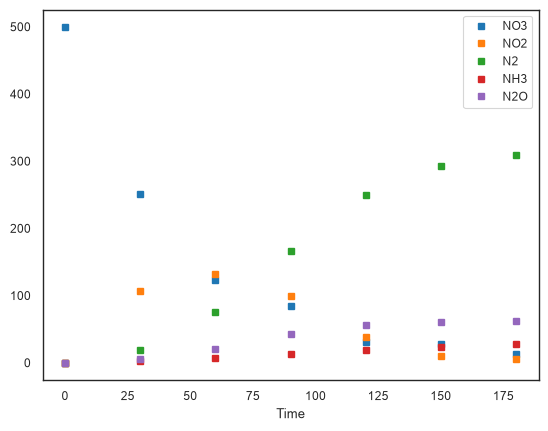

In [21]:
catalysis_data.plot(style='s', x=0);

The theory of catalytic reactions guarantees that the total mass must be conserved.
However, this is not the case in our dataset:

In [22]:
catalysis_data.sum(axis=1)

0    500.00
1    415.09
2    418.32
3    494.71
4    514.28
5    565.40
6    598.95
dtype: float64

This inconsistency suggests the existence of an intermediate unobserved reaction product X.
[(Katsounaros, 2012)](http://www.sciencedirect.com/science/article/pii/S0013468612005208) suggested that the following reaction path shown in the following figure.

The dynamical system associated with the reaction is:
$$
\begin{array}{cc}
\frac{d \left[\mbox{NO}_3^-\right]}{dt} &= -k_1\left[\mbox{NO}_3^-\right], \\
\frac{d\left[\mbox{NO}_2^-\right]}{dt} &= k_1\left[\mbox{NO}_3^-\right] - (k_2 + k_4 +
k_5)[\mbox{NO}_2^-], \\
\frac{d \left[\mbox{X}\right]}{dt} &= k_2 \left[\mbox{NO}_2^-\right] - k_3 [X],\\
\frac{d \left[\mbox{N}_2\right]}{dt} &= k_3 \left[\mbox{X}\right], \\
\frac{d \left[\mbox{NH}_3\right]}{dt} &= k_4 \left[\mbox{NO}_2^-\right],\\
\frac{d \left[\mbox{N}_2O\right]}{dt} &= k_5 \left[\mbox{NO}_2^-\right],
\end{array}
$$
where $[\cdot]$ denotes the concentration of a quantity, and
$k_i > 0$, $i=1,...5$ are the *kinetic rate constants*.

In this problem, I am going to guide you through the calibration of the parameters of this model so that we match the observations.
These problems are also known as *inverse problems*.
The problem can, and should, be formulated in a Bayesian way.
However, in this homework problem we are going to do it using a classical loss-minimization approach.
We will discuss the Bayesian approach for calibrating the same model in a later lecture.

Before you proceed, please read a little bit about the "classical theory of inverse problems:"

### Classical theory of inverse problems

Suppose that you have a model (any model really) that predicts a quantity of interest.
Let's assume that this model has parameters that you do not know.
These parameters could be simple scalars (mass, spring constant, dumping coefficients, etc.) or it could be also be functions (initial conditions, boundary values, spatially distributed constitutive relations, etc.)
Let's denote all these parameters with the vector $x$.
Assume that:
$$
x\in\mathcal{X} \subset\mathbb{R}^d.
$$
Now, let's say we perform an experiment that measures a *noisy* vector:
$$
y\in\mathcal{Y}\subset \mathbb{R}^m.
$$
Assume that, you can use your model *model* to predict $y$.
It does not matter how complicated your model is.
It could be a system of ordinary differential or partial differential equations, or something more complicated.
If it predicts $y$, you can always think of it as a function from the unknown parameter space $\mathcal{X}$ to the space of $y$'s, $\mathcal{Y}\subset\mathbb{R}^m$.
That is, you can think of it as giving rise to a function:
$$
f :\mathcal{X} \rightarrow \mathcal{Y}.
$$

The **inverse problem**, otherwise known as the **model calibration** problem is to find the ``best`` $x\in\mathcal{X}$ so that:
$$
f(x) \approx y.
$$

### Formulation of Inverse Problems as Optimization Problems
Saying that $f(x)\approx y$ is not an exact mathematical statement.
What does it really mean for $f(x)$ to be close to $y$?
To quantify this, let us introduce a *loss metric*:
$$
\ell: \mathcal{Y}\times\mathcal{Y}\rightarrow \mathbb{R},
$$
such that $\ell(f(x),y)$ is how much our prediction is off if we chose the input $x\in\mathcal{X}$.
Equiped with this loss metric, we can formulate the mathematical problem as:
$$
\min_{x\in\mathcal{X}} \ell(f(x),y).
$$

#### The Square Loss
The choice of the metric is somewhat subjective (it depends on what it means to be wrong in your problem).
However, a very common assumption is that to take the *square loss*:
$$
\ell(f(x), y) = \frac{1}{2}\parallel f(x) - y\parallel_2^2 = \frac{1}{2}\sum_{i=1}^m\left(f_i(x)-y_i\right)^2.
$$
For this case, the inverse problem can be formulated as:
$$
\min_{x\in\mathcal{X}}\frac{1}{2}\parallel f(x) - y\parallel_2^2.
$$

#### Solution Methodologies
We basically have to solve an optimization problem.
For the square loss function, if $f(x)$ is linear, then you get the classic least squares problem which has a known solution.
Otherwise, you get what is known as *generalized least squares*.
There are many algorithms that you could use this problem.
Several are implemented in [scipy.optimize](https://docs.scipy.org/doc/scipy/reference/optimize.html).
If you are able to implement your model as a simple python function, then you can use them.
Alternatively, and this is what we are going to do here, we could use Bayesian global optimization instead.
The absolutely, essential thing that you need to provide to these methods is the function they are optimizing, i.e.,
$$
L(x,y) = \ell(f(x),y).
$$

### Back to the catalysis model

Let's now formulate the calibration problem for the catalysis model.
We proceed in several steps.

#### Step 1: Making our life easier by simplifying the notation
Note that this is actually a linear system.
To simplify our notation, let's define:
$$
\begin{array}{ccc}
z_1 &:=& \left[\mbox{NO}_3^-\right],\\
z_2 &:=& \left[\mbox{NO}_2^-\right],\\
z_3 &:=& \left[\mbox{X}\right],\\
z_4 &:=& \left[\mbox{N}_2\right],\\
z_5 &:=& \left[\mbox{NH}_3\right],\\
z_6 &:=& \left[\mbox{N}_2O\right],
\end{array}
$$
the vector:
$$
z = (z_1,z_2,z_3,z_4,z_5,z_6),
$$
and the matrix:
$$
A(k_1,\dots,k_5) = \left(\begin{array}{cccccc}
-k_1 & 0 & 0 & 0 & 0 & 0\\
k_1 & -(k_2+k_4+k_5) & 0 & 0 & 0 & 0\\
0 & k_2 & -k_3 & 0 & 0 & 0\\
0 & 0 & k_3 & 0 & 0 & 0\\
0 & k_4 & 0 & 0 & 0 & 0\\
0 & k_5 & 0 & 0 & 0 & 0
\end{array}\right)\in\mathbb{R}^{6\times 6}.
$$
With these definitions, the dynamical system becomes:
$$
\dot{z} = A(k_1,\dots,k_5)z,
$$
with initial conditions
$$
z(0) = z_0 = (500, 0, 0, 0, 0, 0)\in\mathbb{R}^6,
$$
read directly from the experimental data.
What we are definitely going to need is a solver for this system.
That's easy.
Let's denote the solution of the system at time $t$ by:
$$
z(t;k_1,\dots,k_5).
$$

#### Step 2: Scale the unknown parameters to your best of your abilities
The constraints you have on your parameters, the better.
If you do have constraints, you would have to use constrained optimization algorithms.
The way you scale things depend on the problem.
Here we would think as follows:

+ $k_i$ has units of inverse time. It is proparly appropriate to scale it with the total time which is 180 minutes.
So, let's just multiply $k_i$ with 180. This makes the resulting variable dimensionless:
$$
\hat{x}_i = 180k_i.
$$

+ $k_i$ is positive, therefore $\hat{x_i}$ must be positive.
So, let's just work with the logarithm of $\hat{x_i}$:
$$
x_i = \log \hat{x_i} = \log 180k_i.
$$

+ define the parameter vector:
$$
x = (x_1,\dots,x_5)\in\mathcal{X} = \mathbb{R}^5.
$$

From now on, we will write
$$
A = A(x),
$$
for the matrix of the dynamical system, and
$$
z = z(t;x),
$$
for the solution at $t$ given that the parameters are $x$.

#### Step 3: Making the connection between our model and the experimental measurements
Our experimental data include measurements of everything except $z_3$ at times six (6) time instants:
$$
t_j = 30j\;\mbox{minutes},
$$
$j=1,\dots,6$.

Now, let $Y\in\mathbb{R}^{5\times 6}$ be the experimental measurements:

In [23]:
catalysis_data[1:]

,Time,NO3,NO2,N2,NH3,N2O
1,30,250.95,107.32,18.51,3.33,4.98
2,60,123.66,132.33,74.85,7.34,20.14
3,90,84.47,98.81,166.19,13.14,42.10
4,120,30.24,38.74,249.78,19.54,55.98
5,150,27.94,10.42,292.32,24.07,60.65
6,180,13.54,6.11,309.50,27.26,62.54


You can think of the measurements as vector by flattening the matrix:
$$
y = \operatorname{vec}(Y)\in\mathbb{R}^{30}.
$$
Note that ``vec`` is the vectorization operator.

What is the connection between the solution of the dynamical system $z(t,x)$ and the experimental data?
It is as follows:
$$
\begin{array}{ccc}
z_1(30j;x) &\longrightarrow& Y_{j1},\\
z_2(30j;x) &\longrightarrow& Y_{j2},\\
z_4(30j;x) &\longrightarrow& Y_{j3},\\
z_5(30j;x) &\longrightarrow& Y_{j4},\\
z_6(30j;x) &\longrightarrow& Y_{j5},
\end{array}
$$
for $j=1,\dots,6$.

We are now ready to define a function:
$$
f:\mathcal{X} \rightarrow \mathcal{Y}=\mathbb{R}^{30}_+,
$$
as follows:
+ Define the matrix function:
$$
F:\mathcal{X} \rightarrow \mathbb{R}^{5\times 6},
$$
by:
$$
\begin{array}{ccccc}
F_{j1}(x) &=& z_1(30j;x)&\longrightarrow& Y_{j1},\\
F_{j2}(x) &=& z_2(30j;x) &\longrightarrow& Y_{j2},\\
F_{j3}(x) &=& z_4(30j;x) &\longrightarrow& Y_{j3},\\
F_{j4}(x) &=& z_5(30j;x) &\longrightarrow& Y_{j4},\\
F_{j5}(x) &=& z_6(30j;x) &\longrightarrow& Y_{j5},
\end{array}
$$
+ And flatten that function:
$$
f(x) = \operatorname{vec}(F(x))\in\mathbb{R}^{30}.
$$

Now, we have made the connection with our theoretical formulation of inverse problems crystal clear.

#### Step 4: Programming our ODE solver and the loss function

In [24]:
import scipy.integrate


def A(x):
    """Return the matrix of the catalytic reaction system."""
    # Scale back to the physical rate constants.
    k = np.exp(x) / 180.0
    res = np.zeros((6, 6))
    res[0, 0] = -k[0]
    res[1, 0] = k[0]
    res[1, 1] = -(k[1] + k[3] + k[4])
    res[2, 1] = k[1]
    res[2, 2] = -k[2]
    res[3, 2] = k[2]
    res[4, 1] = k[3]
    res[5, 1] = k[4]
    return res


def g(z, t, x):
    """Right-hand side of the catalytic reaction system."""
    return np.dot(A(x), z)


# Initial conditions and experimental observations.
z0 = np.array([500.0, 0.0, 0.0, 0.0, 0.0, 0.0])
t_exp = 30.0 * np.arange(1, 7)
Y = catalysis_data.iloc[1:, 1:].to_numpy()
y = Y.flatten()


def Z(x, t):
    """Solve from time zero and return states at requested nonnegative times."""
    requested_times = np.asarray(t, dtype=float)
    if np.any(requested_times < 0):
        raise ValueError("Evaluation times must be nonnegative.")
    integration_times = np.unique(np.concatenate(([0.0], requested_times)))
    solution = scipy.integrate.odeint(g, z0, integration_times, args=(x,))
    return solution[np.searchsorted(integration_times, requested_times)]


def F(x, t):
    """Return the modeled species measured in the experiment."""
    solution = Z(x, t)
    return np.hstack([solution[:, :2], solution[:, 3:]])


def f(x, t):
    """Flatten the modeled measurement matrix."""
    return F(x, t).flatten()


def L(x, t, y):
    """Scaled sum-of-squares loss for the measured species."""
    return 0.5 * np.sum((f(x, t) / 500.0 - y / 500.0) ** 2)

#### Step 5: Minimize the loss function

Let's optimize with scipy.optimize:

In [25]:
import scipy.optimize

# Start from a reproducible physically plausible point inside the later search box.
x0 = np.array([1.359, 1.657, 1.347, -0.16, -1.01])
parameter_bounds = [(-2.0, 2.0)] * 5
res = scipy.optimize.minimize(
    L,
    x0,
    args=(t_exp, y),
    method="L-BFGS-B",
    bounds=parameter_bounds,
    options={"maxiter": 2000, "ftol": 1e-12},
)
print(res)
print("Final local-fit loss:", res.fun)

  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 0.007413778544084236
        x: [ 1.359e+00  1.659e+00  1.346e+00 -1.048e+00 -1.603e-01]
      nit: 15
      jac: [-2.238e-08 -7.208e-06  2.282e-06  6.480e-06  6.851e-06]
     nfev: 114
     njev: 19
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>
Final local-fit loss: 0.007413778544084236


And here is how you can visualize the model with the "best" parameters:

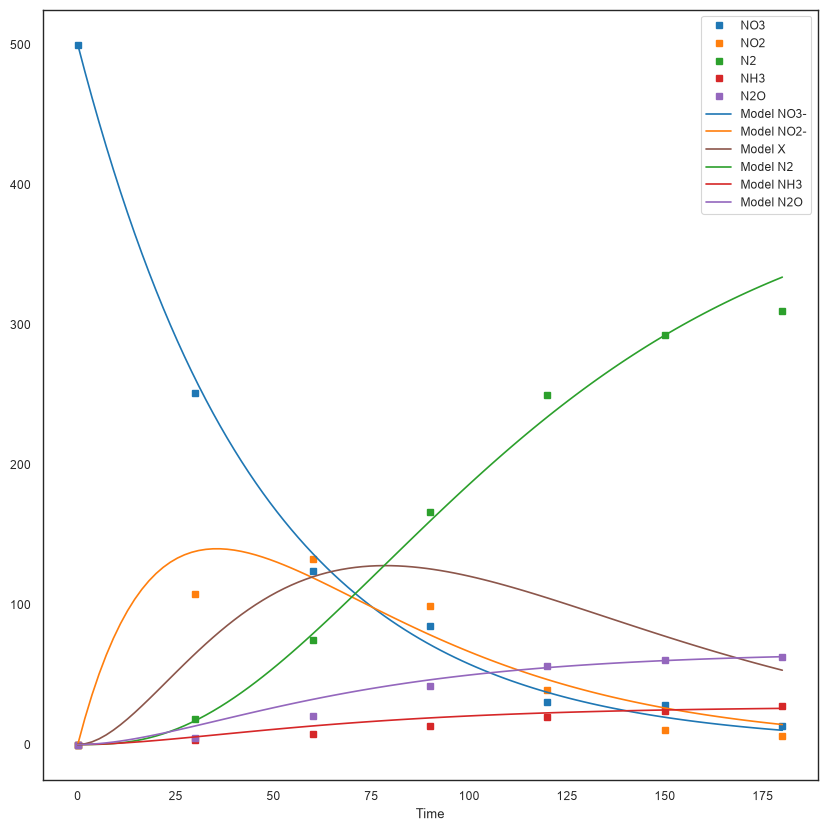

In [26]:
x = res.x
t = np.linspace(0, 180, 100)
x1 = np.array([1.359, 1.657, 1.347, -.16, -1.01])
Yp = Z(x, t)

fig, ax = plt.subplots(figsize=(10, 10))
catalysis_data.plot(ax=ax, style='s', x=0)
ax.plot(t, Yp[:, 0], color=sns.color_palette()[0], label='Model NO3-')
ax.plot(t, Yp[:, 1], color=sns.color_palette()[1], label='Model NO2-')
ax.plot(t, Yp[:, 2], color=sns.color_palette()[5], label='Model X')
ax.plot(t, Yp[:, 3], color=sns.color_palette()[2], label='Model N2')
ax.plot(t, Yp[:, 4], color=sns.color_palette()[3], label='Model NH3')
ax.plot(t, Yp[:, 5], color=sns.color_palette()[4], label='Model N2O')
plt.legend();

Note that the code above will not work every time... Some times it will work and sometimes it won't work.
Run it 3-4 times if it accidentally works.
There are several problems.
Here are the three most relevant in our context:
+ scipy.optimize needs the gradient of the loss function. Since we do not provide it, it tries to get it using numerical differentiation. Numerical differentiation introduces errors...
+ scipy.optimize find a local minimum of the loss function. This may actually be a bad local minimum.
+ okay, this particular model is not very computationally expensive. But imagine trying to calibrate a model that takes a while for a single evaluation (e.g., a finite element model). Then, using scipy.optimize (especially without supplying the derivatives), is doomed to fail.

To overcome these difficulties, you have to use Bayesian global optimization to solve the problem.
Note that in the hands-on activities, we introduced this code:

In [27]:
def ei(m, sigma, ymax, psi=0.0):
    """Expected improvement for maximizing a Gaussian-process objective."""
    m = np.asarray(m, dtype=float)
    sigma = np.asarray(sigma, dtype=float)
    safe_sigma = np.maximum(sigma, 1e-12)
    u = (m - ymax - psi) / safe_sigma
    improvement = safe_sigma * (u * st.norm.cdf(u) + st.norm.pdf(u))
    return np.where(sigma > 0.0, improvement, 0.0)


def maximize(f, gpr, domain, num_candidates=10000, alpha=ei, psi=0.0, max_it=6):
    """Maximize a black-box function using Gaussian-process expected improvement."""
    domain = np.asarray(domain, dtype=float)
    dim = gpr.X.shape[1]
    if domain.shape != (dim, 2):
        raise ValueError(f"domain must have shape ({dim}, 2)")
    if np.any(domain[:, 0] >= domain[:, 1]):
        raise ValueError("Each lower domain bound must be below its upper bound.")

    print("Iteration\tBest loss\tBest expected improvement")
    for count in range(max_it):
        X_design = domain[:, 0] + (domain[:, 1] - domain[:, 0]) * np.random.rand(
            num_candidates, dim
        )
        mean, variance = gpr.predict(X_design)
        sigma = np.sqrt(np.maximum(variance, 0.0))
        acquisition_values = alpha(mean, sigma, float(gpr.Y.max()), psi=psi)
        selected_index = int(np.argmax(acquisition_values))
        selected_x = X_design[selected_index : selected_index + 1]
        selected_y = np.asarray(f(selected_x[0])).reshape(1, 1)

        gpr.set_XY(np.vstack([gpr.X, selected_x]), np.vstack([gpr.Y, selected_y]))
        best_index = int(np.argmax(gpr.Y[:, 0]))
        best_objective = float(gpr.Y[best_index, 0])
        print(
            f"{count + 1}\t\t{-best_objective:.6f}\t"
            f"{float(acquisition_values[selected_index, 0]):.6f}"
        )

    best_index = int(np.argmax(gpr.Y[:, 0]))
    return np.asarray(gpr.X[best_index]).copy(), float(gpr.Y[best_index, 0]), gpr

The code *maximizes* a function, but you want to *minimize* the loss.
To recast the problem as a maximization problem, you need to work with *minus the loss*.
Also, the code does not allow for a function with extra parameters (like the ``t_exp`` and the ``y`` we have for ``L``).
Here is the function that you should be optimizing:

In [28]:
h = lambda x: -L(x, t_exp, y)

## Part A - Perform multivariate Gaussian process regression on an initial set of data

We are going to search for the best parameters $x$ within the set $[-2,2]^5$.
Consider the following two datasets consisting of parameter and minus loss pairs:

In [29]:
# Initial training points
n_init_train = 100
X_init_train = -2.0 + 4.0 * np.random.rand(n_init_train, 5)
Y_init_train = np.array([h(x) for x in X_init_train])[:, None]

Use a squared exponential covariance function with automatic relevance determination to do Gaussian process regression with ``X_init_train`` and ``Y_init_train``.

Hint: You may want to experiment by constraining the likelihood noise of your model to be very small, say $10^{-6}$. This is because the observations of the loss do not really have any noise.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I use an ARD squared-exponential kernel because the response is a smooth function of five parameters and each input can have a different lengthscale. The loss evaluations are deterministic, so I fix the Gaussian likelihood variance at $10^{-6}$. The GP is trained on the 100 initial parameter-loss pairs; its optimized lengthscales are reported in Part B.

</div>

In [30]:
# Fit an ARD squared-exponential GP to the deterministic loss evaluations.
np.random.seed(53908)
n_init_train = 100
X_init_train = -2.0 + 4.0 * np.random.rand(n_init_train, 5)
Y_init_train = np.array([h(x) for x in X_init_train])[:, None]

initial_kernel = GPy.kern.RBF(
    input_dim=5,
    variance=max(float(np.var(Y_init_train)), 1e-6),
    lengthscale=np.ones(5),
    ARD=True,
)
gpr = GPy.models.GPRegression(X_init_train, Y_init_train, initial_kernel)
gpr.Gaussian_noise.variance.fix(1e-6)
gpr.optimize_restarts(num_restarts=3, robust=True, verbose=False)
print("Initial design size:", X_init_train.shape[0])
print("Best initial loss:", -float(np.max(Y_init_train)))
print("Optimized ARD lengthscales:", np.asarray(gpr.kern.lengthscale).ravel())

Initial design size: 100
Best initial loss: 0.04786829430502855
Optimized ARD lengthscales: [2.18001918 3.52406288 5.29850765 2.77249477 4.48805249]


## Part B - Inspecting your model

Use the lengthscale information to rank the model parameters according their effect on the calibration loss.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** A smaller ARD lengthscale indicates that the fitted loss varies more rapidly with that parameter, so I rank the parameters from the shortest to the longest lengthscale. For this fitted model the order is $x_1$, $x_4$, $x_2$, $x_5$, then $x_3$. This is a qualitative ranking for this GP fit, not a causal statement.

</div>

In [31]:
lengthscales = np.asarray(gpr.kern.lengthscale).ravel()
parameter_ranking = np.argsort(lengthscales)
for rank, parameter_index in enumerate(parameter_ranking, start=1):
    print(
        f"{rank}. x_{parameter_index + 1}: lengthscale="
        f"{lengthscales[parameter_index]:.3f}"
    )
print("Smaller ARD lengthscales indicate stronger variation in the loss along that parameter.")

1. x_1: lengthscale=2.180
2. x_4: lengthscale=2.772
3. x_2: lengthscale=3.524
4. x_5: lengthscale=4.488
5. x_3: lengthscale=5.299
Smaller ARD lengthscales indicate stronger variation in the loss along that parameter.


## Part C - Diagnostics

Here are some test data:

In [32]:
# Test points
n_test = 50
X_test = -2.0 + 4.0 * np.random.rand(n_test, 5)
Y_test = np.array([h(x) for x in X_test])[:, None]

Do the following:

+ Predictions vs observations plot
+ Standardized errors plot

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** The held-out predictions follow the one-to-one line closely. The 50-point test set has an RMSE of about $0.081$ and empirical 95% interval coverage of $90\%$. Most standardized errors are within $\pm2$, but a few are larger, including one at about $-6.7$. The surrogate is accurate enough to guide the search, but its uncertainty is somewhat too small in some regions.

</div>

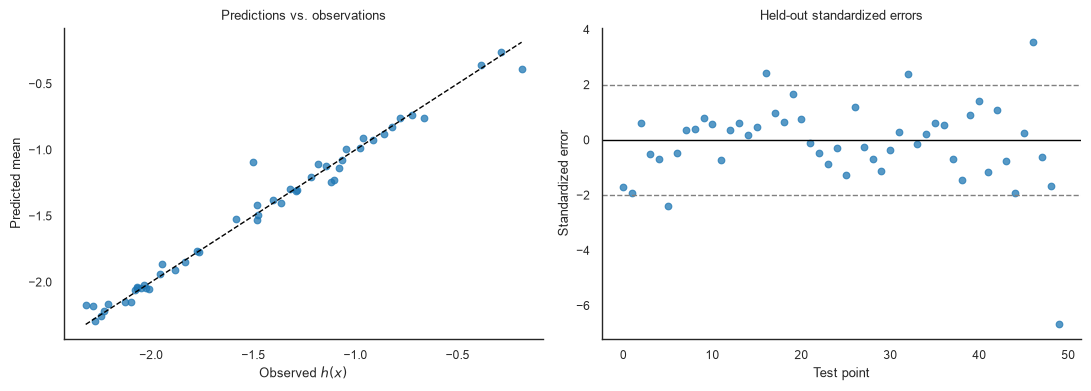

Test RMSE: 0.0810
Empirical 95% interval coverage: 90.0%


In [33]:
# Evaluate the GP on held-out points and inspect calibration diagnostics.
mean_test, variance_test = gpr.predict(X_test)
std_test = np.sqrt(np.maximum(variance_test, 0.0))
standardized_errors = (Y_test - mean_test) / np.maximum(std_test, 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(Y_test, mean_test, alpha=0.75)
plot_limits = [
    min(float(Y_test.min()), float(mean_test.min())),
    max(float(Y_test.max()), float(mean_test.max())),
]
axes[0].plot(plot_limits, plot_limits, "k--", linewidth=1)
axes[0].set(xlabel="Observed $h(x)$", ylabel="Predicted mean", title="Predictions vs. observations")

axes[1].scatter(np.arange(n_test), standardized_errors, alpha=0.75)
axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].axhline(2.0, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(-2.0, color="gray", linestyle="--", linewidth=1)
axes[1].set(xlabel="Test point", ylabel="Standardized error", title="Held-out standardized errors")
sns.despine()
plt.tight_layout()
plt.show()

rmse = np.sqrt(np.mean((Y_test - mean_test) ** 2))
coverage_95 = np.mean(np.abs(Y_test - mean_test) <= 1.96 * std_test)
print(f"Test RMSE: {rmse:.4f}")
print(f"Empirical 95% interval coverage: {coverage_95:.1%}")

## Part D - Calibrate the model with Bayesian global optimization

Now use Bayesian global optimization with expected improvement to calibrate the model using the GP that you built above as the starting point. Do not expect this to give you a perfect model. But it will be better than nothing. We will get the best possible model in the next homework assignment.

Hint: Here you basically need to read the docstring of ``maximize`` and use it correctly.

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

**Answer:** I maximize the negative scaled loss using expected improvement over $[-2,2]^5$. Starting from the 100-point GP design, 20 evaluations reduced the best observed loss from about $0.0479$ to $0.0137$. The selected vector and fitted reaction curves are shown below. This is an approximate result under a limited evaluation budget; the separate bounded local optimizer found a lower loss from its supplied starting point, so the BO result should not be interpreted as a guaranteed global optimum.

</div>

In [34]:
domain = np.array([[-2.0, 2.0]] * 5)

# Expected-improvement search adds twenty evaluations to the 100-point design.
x_opt, best_objective, gpr = maximize(
    h,
    gpr,
    domain,
    num_candidates=10000,
    max_it=20,
)
best_loss = -best_objective
print("Best parameter vector:", x_opt)
print(f"Best loss from Bayesian optimization: {best_loss:.6f}")

Iteration	Best loss	Best expected improvement


1		0.047868	0.132478


2		0.037600	0.045186


3		0.037600	0.039355


4		0.035590	0.024412


...

16		0.013685	0.000006


17		0.013685	0.000404


18		0.013685	0.000000


19		0.013685	0.000000


20		0.013685	0.000567
Best parameter vector: [ 1.33498997  1.83238618  0.97412198 -1.1722161  -0.35179064]
Best loss from Bayesian optimization: 0.013685


Use this code to plot your calibrated model:

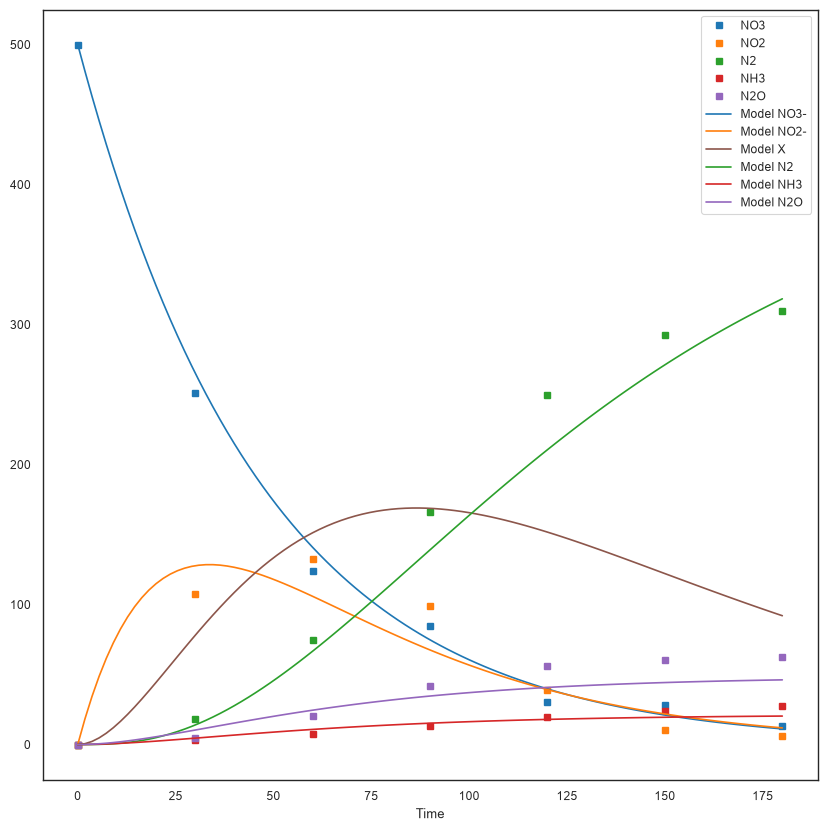

In [35]:
x = x_opt
t = np.linspace(0, 180, 100)
x1 = np.array([1.359, 1.657, 1.347, -.16, -1.01])
Yp = Z(x, t)

fig, ax = plt.subplots(figsize=(10, 10))
catalysis_data.plot(ax=ax, style='s', x=0)
ax.plot(t, Yp[:, 0], color=sns.color_palette()[0], label='Model NO3-')
ax.plot(t, Yp[:, 1], color=sns.color_palette()[1], label='Model NO2-')
ax.plot(t, Yp[:, 2], color=sns.color_palette()[5], label='Model X')
ax.plot(t, Yp[:, 3], color=sns.color_palette()[2], label='Model N2')
ax.plot(t, Yp[:, 4], color=sns.color_palette()[3], label='Model NH3')
ax.plot(t, Yp[:, 5], color=sns.color_palette()[4], label='Model N2O')
plt.legend();